<a href="https://colab.research.google.com/github/Kristel-MF/examen1-pedidos/blob/main/02_process_mining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import pandas as pd
from google.colab import userdata
import warnings

warnings.filterwarnings("ignore")
# 1. Clonar el repositorio
if not os.path.exists("/content/repo"):
    REPO = "Kristel-MF/examen1-pedidos"
    TOKEN = userdata.get("GITHUB_TOKEN")
    !git clone -q https://{TOKEN}@github.com/{REPO}.git /content/repo

# 2. Entrar a la carpeta donde están los scripts
%cd /content/repo/examen1_info-main/examen1_info-main/scripts

# 3. Instalar pm4py
!pip install -q pm4py

# 4. Cargar los datos desde la carpeta raw
ruta_csv = "../datos/raw/caso_02_pedidos.csv"

if os.path.exists(ruta_csv):
    df_raw = pd.read_csv(ruta_csv)
    print("¡ÉXITO! Se cargó el archivo correctamente. Muestra de datos:")
    display(df_raw.head())
else:
    print(f"No se encontró el archivo en: {os.path.abspath(ruta_csv)}")

/content/repo/examen1_info-main/examen1_info-main/scripts
¡ÉXITO! Se cargó el archivo correctamente. Muestra de datos:


,case_id,activity,timestamp,resource,categoria,monto,metodo_pago,region,transportista,cantidad_productos,canal_venta,fecha_prometida
0,PED00653,Pedido recibido,2026-03-02 02:02:11,Sistema,Electrónica,1148.03,Transferencia,Caribe,EnvíaYa,1,Web,2026-03-08
1,PED01890,Pedido recibido,2026-03-02 02:58:04,Sistema,Alimentos,76.46,Transferencia,Central,TransRápido,2,Teléfono,2026-03-06
2,PED00991,Pedido recibido,2026-03-02 05:25:23,Sistema,Ropa,93.74,Tarjeta,Norte,LogiSur,1,Web,2026-03-08
3,PED01890,Validación,2026-03-02 08:03:00,Agente_Ventas_02,Alimentos,76.46,Transferencia,Central,TransRápido,2,Teléfono,2026-03-06
4,PED00653,Validación,2026-03-02 08:05:00,Agente_Ventas_05,Electrónica,1148.03,Transferencia,Caribe,EnvíaYa,1,Web,2026-03-08


/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:254: UserWarning: Some rows of the Pandas data frame have been removed because of empty case IDs, activity labels, or timestamps to ensure the correct functioning of PM4Py's algorithms.
  warnings.warn(


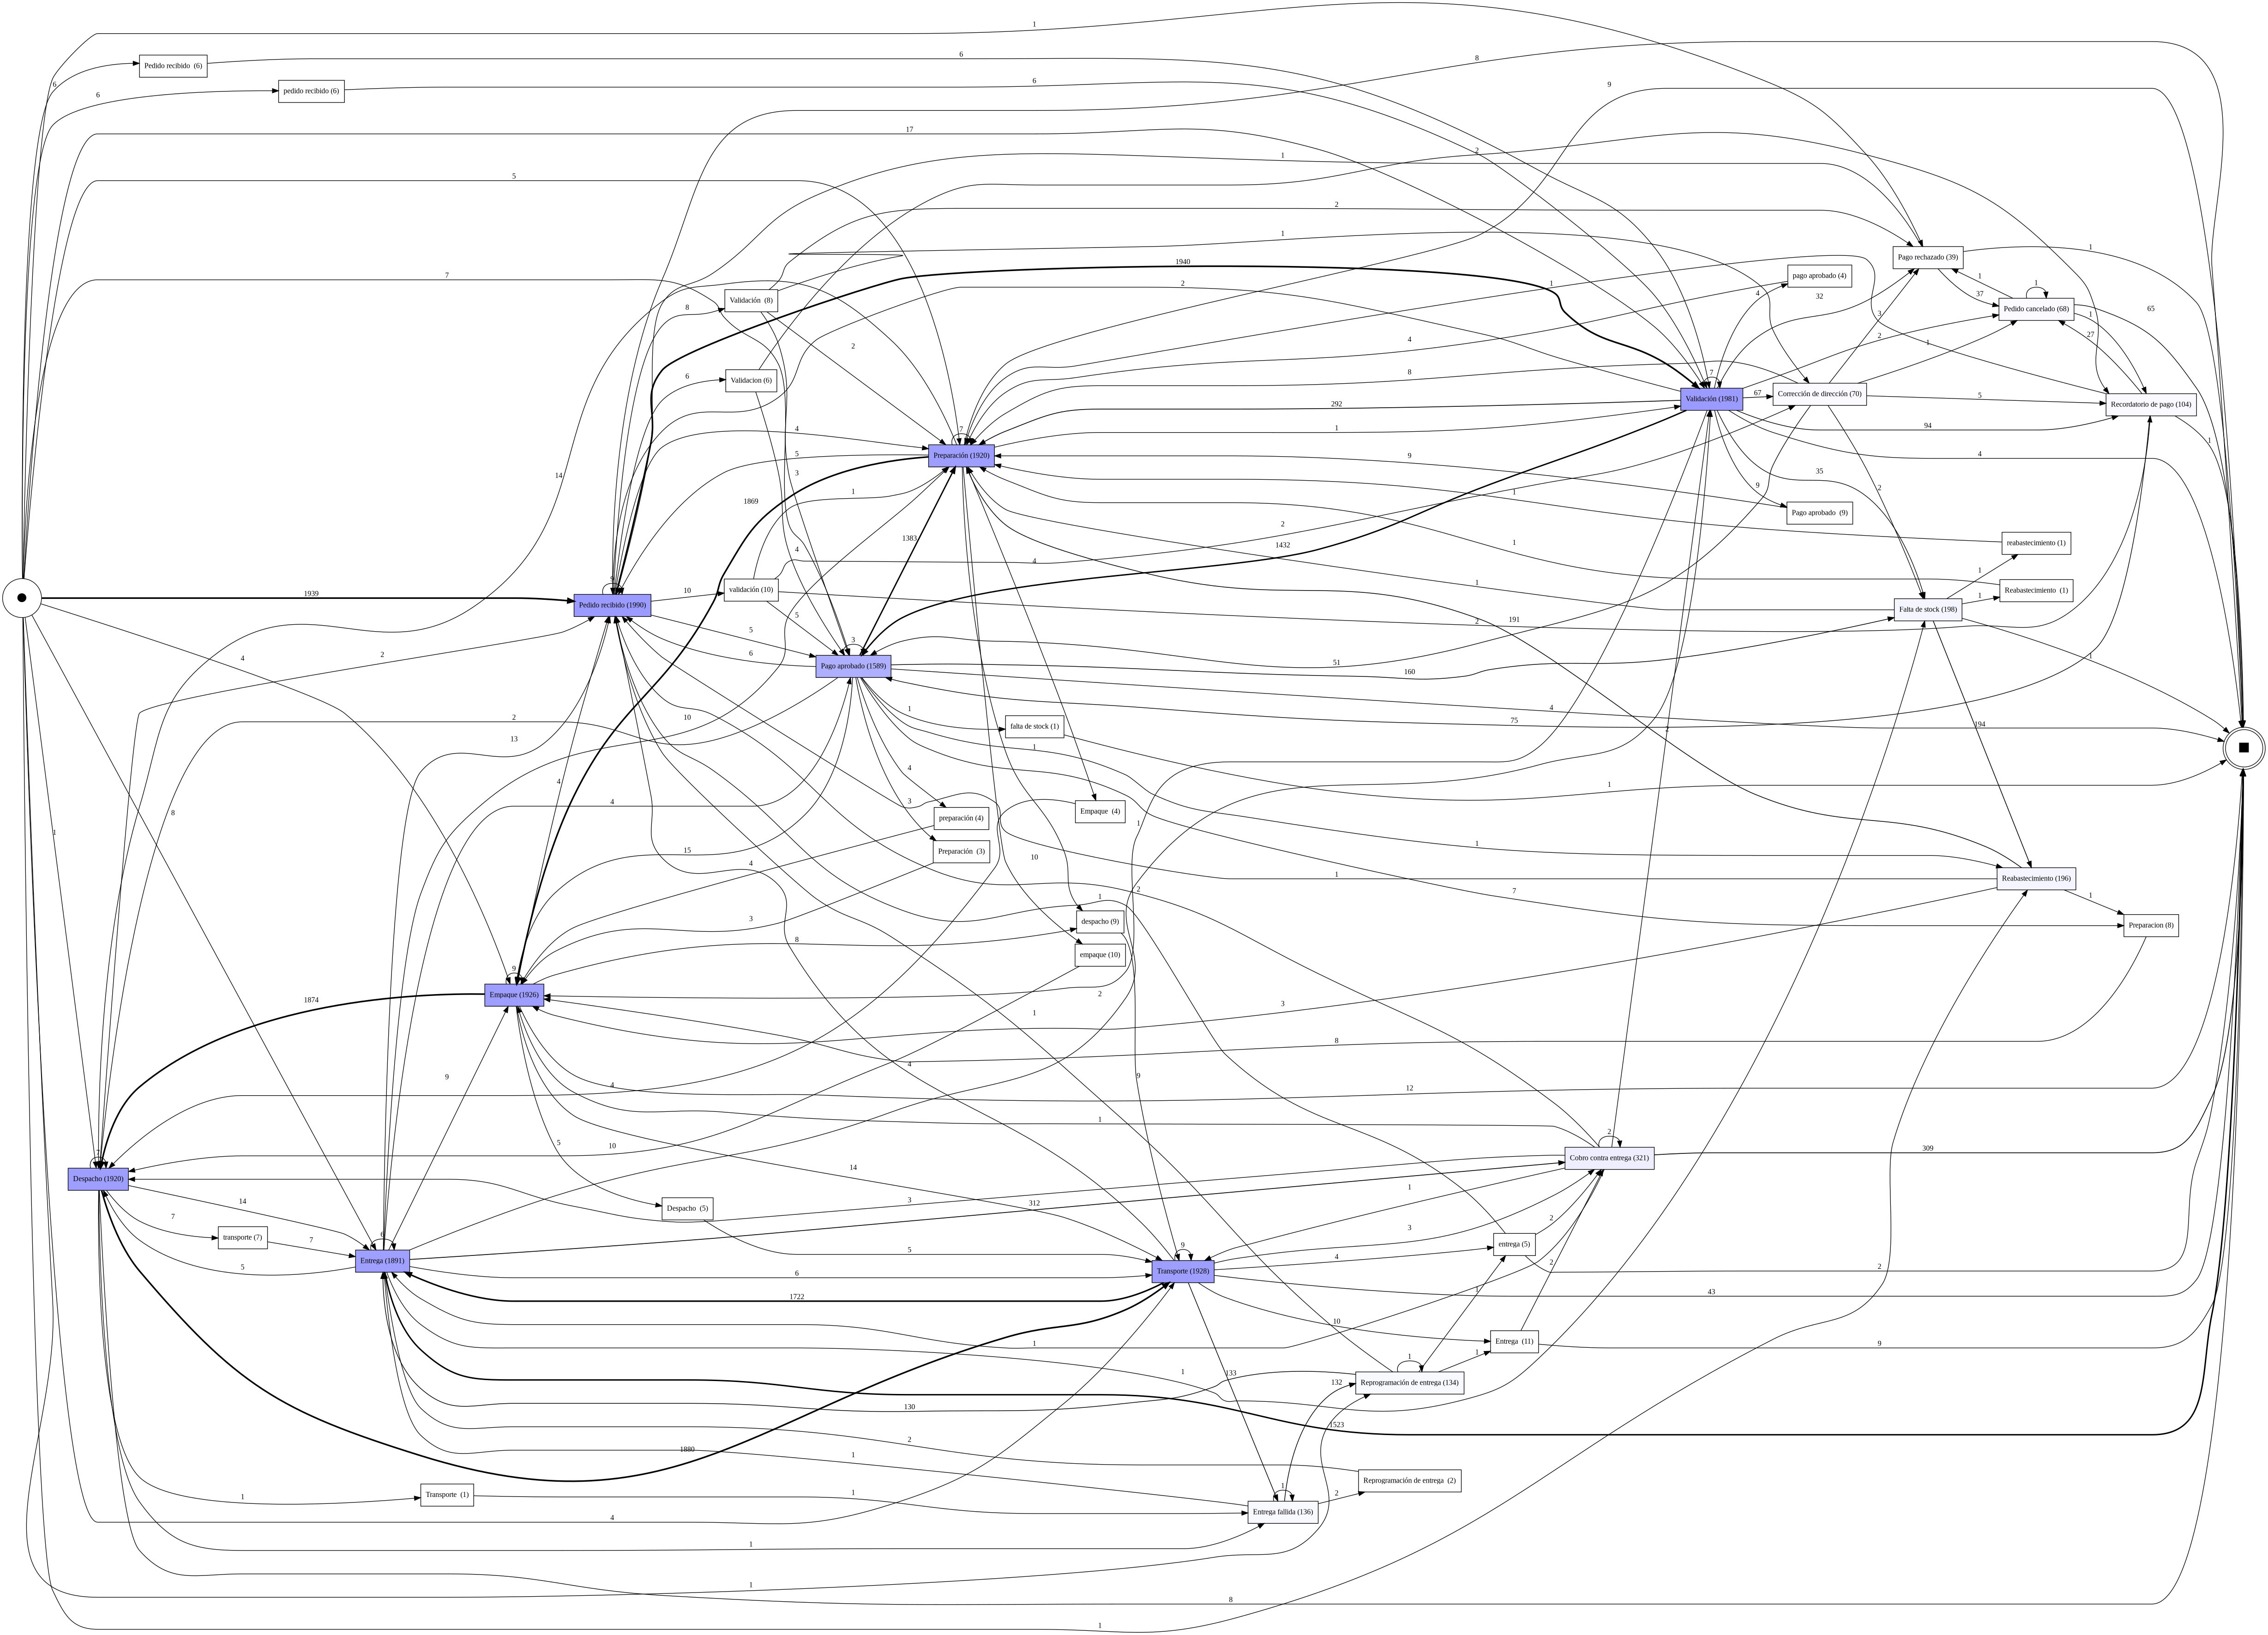


--- Resumen del Event Log ---
Número total de eventos: 16532
Número total de casos (pedidos): 2000


In [13]:
import pandas as pd
import pm4py

# 1. Convertir la columna 'timestamp' manejando formatos de fecha mixtos
df_raw["timestamp"] = pd.to_datetime(df_raw["timestamp"], format="mixed")

# 2. Renombrar las columnas en inglés a las llaves que exige PM4Py
df_renamed = df_raw.rename(
    columns={
        "case_id": "case:concept:name",
        "activity": "concept:name",
        "timestamp": "time:timestamp",
    }
)

# 3. Formatear como Event Log para PM4Py
event_log = pm4py.format_dataframe(
    df_renamed,
    case_id="case:concept:name",
    activity_key="concept:name",
    timestamp_key="time:timestamp",
)

# 4. Descubrir y mostrar el Mapa de Procesos (Directly-Follows Graph)
dfg, start_activities, end_activities = pm4py.discover_dfg(event_log)
pm4py.view_dfg(dfg, start_activities, end_activities)

# 5. Imprimir resumen básico del log
print("\n--- Resumen del Event Log ---")
print(f"Número total de eventos: {len(event_log)}")
print(f"Número total de casos (pedidos): {len(event_log['case:concept:name'].unique())}")


In [15]:
# 1. Obtener variantes filtradas por frecuencia usando pm4py
variants_count = pm4py.get_variants(event_log)
print(f"Total de variantes únicas encontradas: {len(variants_count)}")

# 2. Ordenar directamente por el conteo (valor entero)
top_variants = sorted(
    variants_count.items(), key=lambda x: x[1], reverse=True
)[:5]

print("\nTop 5 Variantes más frecuentes:")
for idx, (variant, count) in enumerate(top_variants, 1):
    print(f"Variante {idx} ({count} casos): {variant}")

Total de variantes únicas encontradas: 174

Top 5 Variantes más frecuentes:
Variante 1 (1058 casos): ('Pedido recibido', 'Validación', 'Pago aprobado', 'Preparación', 'Empaque', 'Despacho', 'Transporte', 'Entrega')
Variante 2 (198 casos): ('Pedido recibido', 'Validación', 'Preparación', 'Empaque', 'Despacho', 'Transporte', 'Entrega', 'Cobro contra entrega')
Variante 3 (113 casos): ('Pedido recibido', 'Validación', 'Pago aprobado', 'Falta de stock', 'Reabastecimiento', 'Preparación', 'Empaque', 'Despacho', 'Transporte', 'Entrega')
Variante 4 (65 casos): ('Pedido recibido', 'Validación', 'Pago aprobado', 'Preparación', 'Empaque', 'Despacho', 'Transporte', 'Entrega fallida', 'Reprogramación de entrega', 'Entrega')
Variante 5 (54 casos): ('Pedido recibido', 'Validación', 'Recordatorio de pago', 'Pago aprobado', 'Preparación', 'Empaque', 'Despacho', 'Transporte', 'Entrega')


In [16]:
# Obtener tiempo de procesamiento/duración por caso
case_durations = pm4py.get_all_case_durations(event_log)

# Convertir duraciones (en segundos) a días para facilitar lectura
import numpy as np

durations_in_days = [d / (3600 * 24) for d in case_durations]

print("--- Estadísticas de Duraciones de Casos ---")
print(f"Duración promedio: {np.mean(durations_in_days):.2f} días")
print(f"Duración mediana: {np.median(durations_in_days):.2f} días")
print(f"Duración mínima: {np.min(durations_in_days):.2f} días")
print(f"Duración máxima: {np.max(durations_in_days):.2f} días")

--- Estadísticas de Duraciones de Casos ---
Duración promedio: 10.10 días
Duración mediana: 4.19 días
Duración mínima: 0.04 días
Duración máxima: 269.84 días


In [17]:
# Ver número de eventos por tipo de actividad
activities_count = pm4py.get_event_attribute_values(event_log, "concept:name")
print("Frecuencia de actividades:")
for act, count in activities_count.items():
    print(f" - {act}: {count}")

Frecuencia de actividades:
 - Pedido recibido: 1990
 - Validación: 1981
 - Transporte: 1928
 - Empaque: 1926
 - Preparación: 1920
 - Despacho: 1920
 - Entrega: 1891
 - Pago aprobado: 1589
 - Cobro contra entrega: 321
 - Falta de stock: 198
 - Reabastecimiento: 196
 - Entrega fallida: 136
 - Reprogramación de entrega: 134
 - Recordatorio de pago: 104
 - Corrección de dirección: 70
 - Pedido cancelado: 68
 - Pago rechazado: 39
 - Entrega : 11
 - validación: 10
 - empaque: 10
 - Pago aprobado : 9
 - despacho: 9
 - Preparacion: 8
 - Validación : 8
 - transporte: 7
 - pedido recibido: 6
 - Pedido recibido : 6
 - Validacion: 6
 - entrega: 5
 - Despacho : 5
 - preparación: 4
 - Empaque : 4
 - pago aprobado: 4
 - Preparación : 3
 - Reprogramación de entrega : 2
 - Reabastecimiento : 1
 - falta de stock: 1
 - reabastecimiento: 1
 - Transporte : 1


In [18]:
# Calcular actividades repetidas en el mismo caso
from collections import Counter


def count_rework(log):
    rework_cases = 0
    total_cases = len(log["case:concept:name"].unique())

    # Agrupar por caso
    grouped = log.groupby("case:concept:name")["concept:name"].apply(list)

    for case_id, activities in grouped.items():
        counts = Counter(activities)
        # Si alguna actividad se repite más de 1 vez en el mismo caso
        if any(freq > 1 for freq in counts.values()):
            rework_cases += 1

    print(f"Casos con re-trabajo/bucles: {rework_cases} de {total_cases}")
    print(f"Porcentaje de re-trabajo: {(rework_cases / total_cases) * 100:.2f}%")


count_rework(df_renamed)

Casos con re-trabajo/bucles: 61 de 2000
Porcentaje de re-trabajo: 3.05%


In [19]:
import os

# Crear directorio de salida dentro de entregas si no existe
output_dir = "../entregas/corte_2_process_mining/"
os.makedirs(output_dir, exist_ok=True)

# Guardar el mapa de procesos como imagen PNG
pm4py.save_vis_dfg(
    dfg,
    start_activities,
    end_activities,
    os.path.join(output_dir, "mapa_procesos_dfg.png"),
)
print("¡Imagen del mapa de procesos guardada con éxito en entregas!")

¡Imagen del mapa de procesos guardada con éxito en entregas!
